# DS2002 · Critique and Redesign

**Studio — 2026-11-11 · Fall 2026**

---

## From Monday's cookbook to a graded chart

Monday's **Visualization for Decisions** notebook is a recipe book: sorted bars, labeled lines, `finish()`, and titles computed from the data. Today you run the **six-point rubric** on purposefully bad charts, rebuild them twice (mechanics first, then argument), and apply the same lens to your midterm work.

**Lab 11** uses the *same* sample data and the same rubric. It is due **Wednesday, November 18, 11:59pm ET** so you can finish midterm presentations first. If you have not opened Monday's notebook since then, skim the cheat sheet at the end before you start the studio charts.

### Monday's four rules meet the rubric

The presentation rubric is how we grade. Monday's four rules are how you fix charts before they hit a slide.

| Monday rule | Rubric criteria it mainly hits |
|---|---|
| One chart, one message | Title states a finding; no wasted ink |
| Title states the finding | Title states a finding |
| Label axes and name the unit | Axes labeled with units |
| Sort by value (unless time) | Readable; often honest scale |
| Pick the right chart type | Right chart for the question |
| Truncated bars, raw counts, overplotting | Honest scale; readable |

Run the setup cell next. It defines `score()` (the rubric) and `finish()` (the same helper from Monday).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()

print('ready')

ready


### The six-point rubric

Score any chart out of 6. This is the same rubric used on both project presentations and Lab 11.

| # | Criterion | Fails when |
|---|---|---|
| 1 | Title states a finding | Title names the columns |
| 2 | Axes labeled with units | "Revenue" with no currency; no axis label |
| 3 | Right chart for the question | Pie for comparison; bars for a trend |
| 4 | Honest scale | Truncated bar axis; unnormalized comparison |
| 5 | Readable | Overlapping labels, clipped text, unsorted categories |
| 6 | No wasted ink | Decoration, redundant legends, chart junk |

Before you call a chart done, also run Monday's four questions: what one sentence does it prove; is that the title; are units obvious; is anything on the page not carrying information?

### Chart 1 — the pie chart

Same categories as Monday's worked example. Pie charts are not on the chart-picker list for a reason.

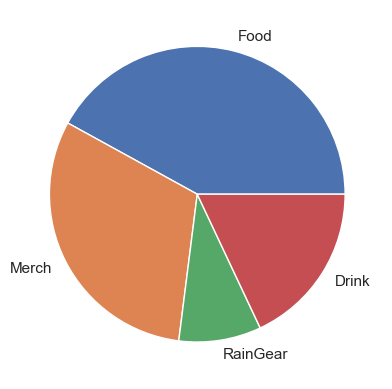

In [2]:
cats = ['Food', 'Merch', 'RainGear', 'Drink']
vals = [4200, 3100, 900, 1800]
plt.pie(vals, labels=cats)
plt.show()

**TODO:** score it with `score(...)`. Then say in a comment which two slices you cannot rank by eye — that is the concrete cost of the chart type.

In [3]:
score(title=False, axes=False, chart_type=False, scale=True, readable=True, ink=True)

# Ambiguous by eye: Food vs Merch. They are 42% and 31%, but neither slice starts on a common
# baseline and the chart prints no values, so you are comparing two angles at different
# rotations. Is Food a little bigger or a lot bigger? The pie cannot say; a bar can.

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 3/6


3

**Iteration 1 — fix the mechanics (Monday Recipe 1).**

**TODO:** rebuild as a sorted horizontal bar on `fig, ax`. Use `finish()` with a title that states a finding, `revenue (USD)` on the axis, `ax.bar_label` for the dollar amounts, and `BLUE` bars. Do not worry yet whether the message is the *best* one available.

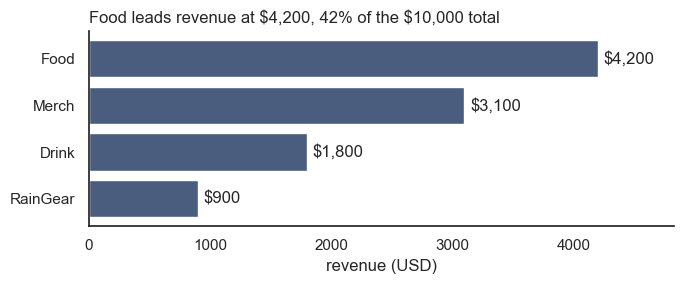

In [4]:
totals = pd.Series(vals, index=cats).sort_values()
share = totals.max() / totals.sum()

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(totals.index, totals.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in totals.values], padding=4)
ax.set_xlim(0, totals.max() * 1.15)
finish(ax, f'{totals.idxmax()} leads revenue at ${totals.max():,.0f}, {share:.0%} of the ${totals.sum():,.0f} total',
       xlabel='revenue (USD)')
plt.show()

**Iteration 2 — sharpen the argument (Monday Recipe 2).**

A sorted bar of totals probably says food leads revenue. True, and not very useful.

**TODO:** rain gear is tiny in total but strong when it actually sells. Chart `revenue_per_game` below: highlight RainGear in `RUST`, grey the rest, and write a title that states *that* finding.

In [5]:
detail = pd.DataFrame({
    'category': ['Food', 'Merch', 'RainGear', 'Drink'],
    'revenue': [4200, 3100, 900, 1800],
    'games_sold_in': [6, 6, 2, 6],   # rain gear only moves on wet days
}).set_index('category')
detail['revenue_per_game'] = detail['revenue'] / detail['games_sold_in']
detail

,revenue,games_sold_in,revenue_per_game
category,,,
Food,4200,6,700.000000
Merch,3100,6,516.666667
RainGear,900,2,450.000000
Drink,1800,6,300.000000


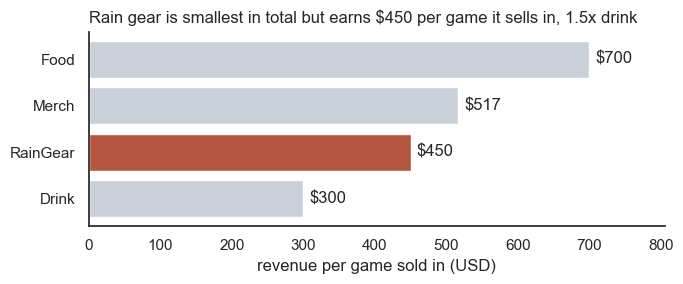

In [6]:
per_game = detail['revenue_per_game'].sort_values()
rg = per_game['RainGear']
drink = per_game['Drink']

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(per_game.index, per_game.values,
               color=[RUST if k == 'RainGear' else GRAY for k in per_game.index])
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in per_game.values], padding=4)
ax.set_xlim(0, per_game.max() * 1.15)
finish(ax, f'Rain gear is smallest in total but earns ${rg:,.0f} per game it sells in, {rg / drink:.1f}x drink',
       xlabel='revenue per game sold in (USD)')
plt.show()

### Chart 2 — truncated axis (Monday mistake #1)

**TODO:** score this chart, name the specific problem, rebuild with the y-axis starting at zero, and use `finish()` with an honest title — including if the honest answer is "these zones are within a few percent of each other."

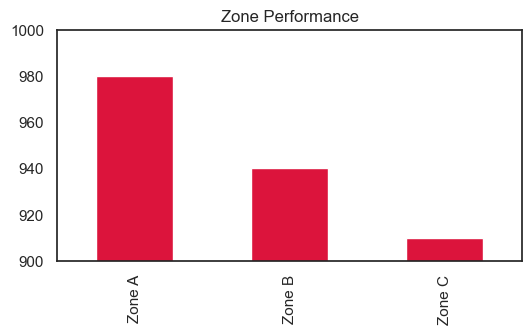

In [7]:
zones = pd.Series({'Zone A': 980, 'Zone B': 940, 'Zone C': 910})
fig, ax = plt.subplots(figsize=(6, 3))
zones.plot(kind='bar', color='crimson', ax=ax)
ax.set_ylim(900, 1000)
ax.set_title('Zone Performance')
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
PASS - right chart for the question
FAIL - honest scale
PASS - readable
PASS - no wasted ink

score: 3/6


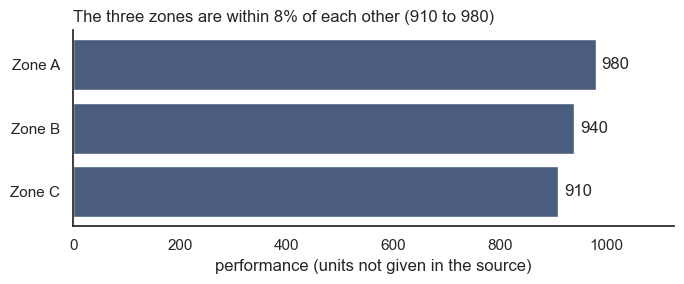

In [8]:
score(title=False, axes=False, chart_type=True, scale=False, readable=True, ink=True)

# Problem: the y-axis starts at 900, so Zone A's bar looks about 4x Zone C's
# (80 vs 10 above the cutoff) when the real gap is 980 vs 910. Bars encode length,
# so a bar axis has to start at zero. The title also names the chart, not a finding,
# and neither axis is labeled. The source gives no unit, so the label below says so.

gap = zones.max() / zones.min() - 1
srt = zones.sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(srt.index, srt.values, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_xlim(0, zones.max() * 1.15)
finish(ax, f'The three zones are within {gap:.0%} of each other ({zones.min():,} to {zones.max():,})',
       xlabel='performance (units not given in the source)')
plt.show()

# Does the gap matter? Not on this evidence: the best zone is 8% above the worst,
# and without a unit or a sense of normal week-to-week variation, that difference is
# not a reason to treat the zones differently.

### Chart 3 — wrong chart type for time (Monday mistakes + Recipe 3)

Stacked bars hide when each series peaks. The staffing story lives in the *timing*.

**TODO:** score the default, then rebuild: one line per zone (or total orders), kickoff at 15.5, and a title with the staffing decision a manager should draw — same pattern as Monday's orders-by-hour example.

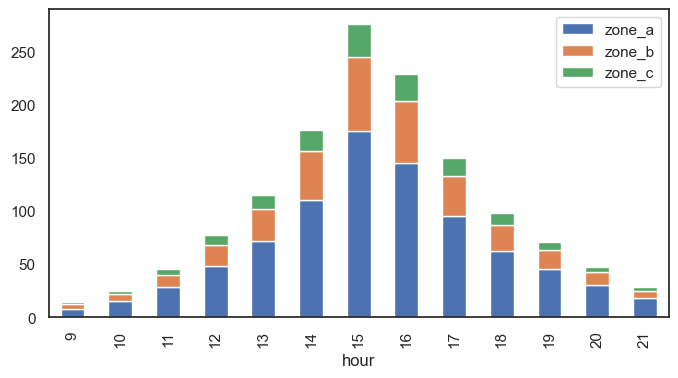

In [9]:
hourly = pd.DataFrame({
    'hour': list(range(9, 22)),
    'zone_a': [8, 15, 28, 48, 72, 110, 175, 145, 95, 62, 45, 30, 18],
    'zone_b': [4, 7, 12, 20, 30, 46, 70, 58, 38, 25, 18, 12, 7],
    'zone_c': [2, 3, 5, 9, 13, 20, 31, 26, 17, 11, 8, 5, 3],
}).set_index('hour')

fig, ax = plt.subplots(figsize=(8, 4))
hourly.plot(kind='bar', stacked=True, ax=ax)
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 3/6


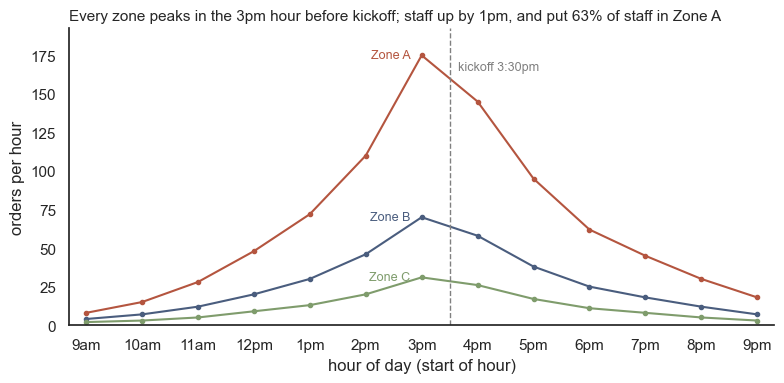

In [10]:
score(title=False, axes=False, chart_type=False, scale=True, readable=True, ink=True)

# Stacked bars force you to read Zone B and Zone C off a floating baseline, so you
# cannot tell whether they peak at the same hour as Zone A. The timing is the story.

KICKOFF = 15.5
peak_hour = hourly.sum(axis=1).idxmax()
peaks = hourly.idxmax()
a_share = hourly.loc[peak_hour, 'zone_a'] / hourly.loc[peak_hour].sum()
assert (peaks == peak_hour).all()  # every zone peaks in the same hour

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in zip(hourly.columns, [RUST, BLUE, '#7f9c6c']):
    ax.plot(hourly.index, hourly[col], marker='o', ms=3, color=color)
    ax.annotate(col.replace('_', ' ').title(), xy=(peak_hour, hourly.loc[peak_hour, col]),
                xytext=(-8, 0), textcoords='offset points', ha='right', va='center', fontsize=9, color=color)
ax.axvline(KICKOFF, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(KICKOFF, hourly.values.max()), xytext=(6, -4),
            textcoords='offset points', fontsize=9, color='gray', va='top')
ax.set_xticks(hourly.index)
ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in hourly.index])
ax.set_ylim(0, hourly.values.max() * 1.1)
ax.set_xlim(hourly.index[0] - 0.3, hourly.index[-1] + 0.3)
finish(ax, f'Every zone peaks in the {peak_hour % 12}pm hour before kickoff; staff up by 1pm, '
           f'and put {a_share:.0%} of staff in Zone A',
       xlabel='hour of day (start of hour)', ylabel='orders per hour', fontsize=11)
plt.show()

### Your own work

Midterm presentations are still on people's minds. Open your **midterm notebook** (or Monday's cookbook if you are not happy with any midterm chart yet). Pick one chart, score it, and do **one** iteration: mechanics or sharper claim.

If it already scores 6, take your strongest chart and try to make the title more specific — compute the number in the title from the same data you plot.

In [11]:
%%capture team_run
# Rerun the midterm pipeline (cleaning, live Open-Meteo weather, join) without echoing its output.
%run team_notebook.ipynb

**Chart I picked:** Q3 in `team_notebook.ipynb`, "Buying peaks before the wind arrives".
It plots the sales index and the max wind gust on two y-axes (`twinx`).

- PASS title states a finding, but loosely, with no date or number.
- PASS axes labeled with units (multiple of baseline, mph).
- FAIL right chart: the claim is about *timing*, but a dual axis invites reading where the lines cross, which means nothing.
- FAIL honest scale: the two y-axes have independent ranges, so how close the peaks look is an accident of the limits matplotlib chose.
- PASS readable, PASS no wasted ink.

**Iteration (mechanics):** two panels stacked on one shared date axis, each starting at zero in its own unit, with each series' peak marked. The title is computed from the same data.

PASS - title states a finding
PASS - axes labeled with units
FAIL - right chart for the question
FAIL - honest scale
PASS - readable
PASS - no wasted ink

score: 4/6


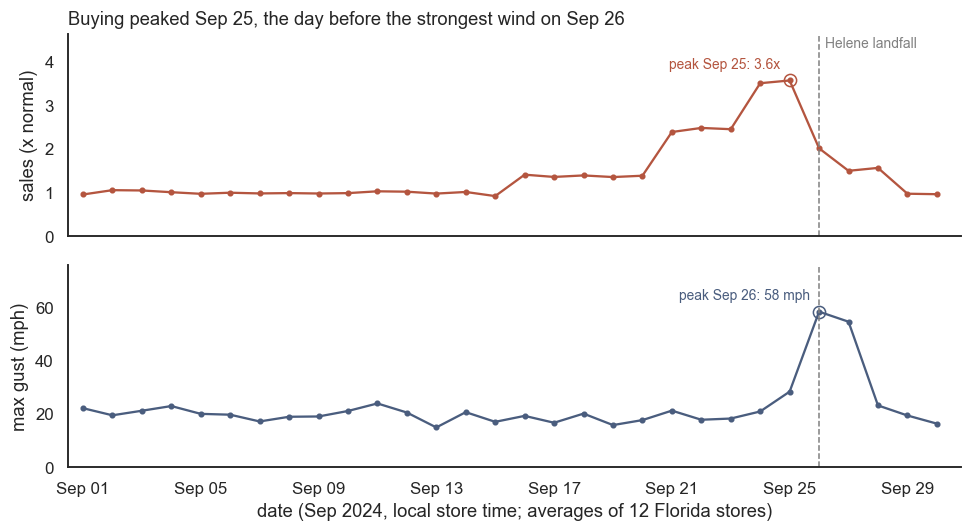

after:
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [12]:
score(title=True, axes=True, chart_type=False, scale=False, readable=True, ink=True)

sales_peak = statewide['units_index'].idxmax()
wind_peak = statewide['max_gust_mph'].idxmax()
lead_days = (wind_peak - sales_peak).days
lead = 'the day' if lead_days == 1 else f'{lead_days} days'

fig, (top, bot) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
panels = [(top, 'units_index', RUST, 'sales (x normal)', 'x', 1),
          (bot, 'max_gust_mph', BLUE, 'max gust (mph)', ' mph', 0)]
for ax, col, color, ylabel, unit, dec in panels:
    s = statewide[col]
    ax.plot(s.index, s.values, marker='o', ms=3, color=color)
    ax.plot(s.idxmax(), s.max(), 'o', ms=8, mfc='none', mec=color)
    ax.annotate(f'peak {s.idxmax():%b %d}: {s.max():.{dec}f}{unit}', xy=(s.idxmax(), s.max()),
                xytext=(-6, 6), textcoords='offset points', ha='right', va='bottom', fontsize=9, color=color)
    ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
    ax.set_ylim(0, s.max() * 1.3)
    ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
top.annotate('Helene landfall', xy=(LANDFALL, statewide['units_index'].max() * 1.28), xytext=(4, 0),
             textcoords='offset points', fontsize=9, color='gray', va='top')
top.set_title(f'Buying peaked {sales_peak:%b %d}, {lead} before the strongest wind on {wind_peak:%b %d}',
              loc='left', fontsize=12)
bot.set_xlabel('date (Sep 2024, local store time; averages of 12 Florida stores)')
bot.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
bot.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
bot.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
fig.tight_layout()
plt.show()

print('after:')
score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

**My score before:** 4/6  **After:** 6/6  **What I changed:** replaced the dual y-axis with two stacked panels on a shared date axis, each starting at zero in its own unit, marked each peak, and swapped the vague title for one computed from the data (peak dates and the gap between them).

---

## Checkpoint (participation)

Report the rubric score of your own chart before and after your redesign, and what you changed (midterm chart or Monday cookbook chart).

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot) into this week's **Studio Checkpoint** in Canvas by **Wednesday, November 18, 11:59pm ET** — same deadline as Lab 11. One submission per person, not per group.

In [13]:
# Checkpoint
chart_i_fixed = 'Midterm Q3 weather chart (team_notebook.ipynb): sales index vs max wind gust, dual y-axis'
score_before = 4
score_after = 6
new_title = f'Buying peaked {sales_peak:%b %d}, {lead} before the strongest wind on {wind_peak:%b %d}'

print('chart:', chart_i_fixed)
print('score:', score_before, '->', score_after)
print('new title:', new_title)

chart: Midterm Q3 weather chart (team_notebook.ipynb): sales index vs max wind gust, dual y-axis
score: 4 -> 6
new title: Buying peaked Sep 25, the day before the strongest wind on Sep 26
